# Análise Exploratória (EDA) — Spotify Full

**Roteiro**
0. Setup e carga
1. Visão geral e grupos de colunas
2. Qualidade dos dados (nulos, duplicados, inconsistências, anomalias)
3. Univariada numérica (distribuições, assimetria, outliers)
4. Univariada categórica e booleanas
5. Evolução temporal
6. Correlações (e redundância entre variáveis)
7. Bivariadas contra a popularidade / streams
8. Nível artista
9. Colunas derivadas: constância, redundância e risco de vazamento


In [1]:
# importação das bibliotecas necessárias
# !pip install pandas numpy matplotlib seaborn

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore") //oculta possíveis erros
sns.set_theme(style="whitegrid", context="notebook") //configurações de gráfico
pd.set_option("display.max_columns", 100) //visualiza até 100 colunas da tabela
pd.set_option("display.max_rows", 200) // até 200 linhas da tabelça
pd.set_option("display.float_format", "{:,.3f}".format) //números decimais serão apresentados com até 3 números após a vírgula
plt.rcParams["figure.dpi"] = 110 //configuração dos gráficos (qualidade)

DATA_PATH = "../data/raw/spotify_full.csv" //caminho para meu arquivo
SEED = 42 //semente 42 por padrão
TARGET = "track_popularity" //analisando popularidade

### Carga com pouca memória
`read_csv` padrão carrega floats em 64 bits e textos longos (título, ids) como objetos — é o que estoura a RAM.
Aqui: (1) pulamos colunas de texto pesadas, (2) floats em 32 bits, (3) leitura em blocos,
(4) textos de baixa cardinalidade viram `category`. Se ainda faltar memória, use `SAMPLE_FRAC`.

In [2]:
#se usar read_csv pode consumir muita memória 

import os, gc //informações do sistema operacional, memória de objetos

# ---- Diagnóstico
print(f"Arquivo: {os.path.getsize(DATA_PATH) / 1024**3:.2f} GB") //mostra o tamanho do meu arquivo em GB
try:
    import psutil //informações da memória do computador
    print(f"RAM livre: {psutil.virtual_memory().available / 1024**3:.1f} GB") //verifica quanta memória tem no meu computador
except ImportError: //se a biblioteca não estiver instalada, ignora
    pass

# ---- Configuração
DROP_COLS   = ["title", "title_normalized", "spotify_id", "album_id", "album_name", "genre_raw"] #colunas não serão carregadas no dataframe 
SAMPLE_FRAC = None      # carrega todas as linhas, se for 0.3 carrega 30% das linhas
CHUNK       = 200_000   #vai ler em blocos de 200 mil linhas 

#colunas que serão guardadadas como float
FLOAT32 = (["energy", "valence", "danceability", "acousticness", "instrumentalness", "speechiness",
            "liveness", "loudness", "tempo", "time_signature", "stream_density", "chart_peak_position",
            "weeks_on_chart", "track_age_days", "energy_loudness_ratio", "mood_index",
            "acoustic_synthetic_ratio", "loudness_war_index", "novelty_score", "hit_probability",
            "fp_energy", "fp_valence", "fp_danceability", "fp_acousticness", "fp_instrumentalness",
            "fp_speechiness", "fp_liveness", "mean_energy_by_artist", "sonic_evolution_score",
            "genre_breadth", "catalog_size", "career_start_year", "career_end_year", "career_span_years",
            "longevity_score", "hit_rate", "artist_stream_mean_log", "artist_stream_median_log",
            "mean_energy_by_decade", "mean_valence_by_decade", "mean_tempo_by_decade",
            "mean_loudness_by_decade", "acousticness_decline_idx", "danceability_trend"])
            # streams_total fica em float64 (valores grandes)
#colunas como booleanas
BOOLS   = ["explicit_flag", "has_audio_features", "streams_total_estimated", "popularity_imputed_aug",
           "is_likely_instrumental", "is_likely_live", "is_likely_spoken_word", "has_anomaly",
           "release_year_precision_aug"]
#colunas categoria
CATEGORY = ["source_dataset", "key_name", "mode_name", "genre_l1", "genre_l2", "streams_source", "era",
            "emotional_arc", "tempo_band", "mood_cluster", "taste_cluster", "anomaly_flags"]
#colunas como string
STRINGS  = ["track_id", "track_artist", "release_date", "chart_date_first"] + CATEGORY

# ---- Leitura em blocos
header  = pd.read_csv(DATA_PATH, nrows=0).columns #le apenas as colunas
usecols = [c for c in header if c not in DROP_COLS] #cria uma lista com colunas que serão carregadas ignorando as que eu tirei
dtypes  = {c: "float32" for c in FLOAT32 if c in usecols} #define que colunas serão guardadas como float
dtypes.update({c: "bool" for c in BOOLS if c in usecols}) #booleanos
dtypes.update({c: str for c in STRINGS if c in usecols}) #string

partes = []
for chunk in pd.read_csv(DATA_PATH, usecols=usecols, dtype=dtypes, chunksize=CHUNK):
    if SAMPLE_FRAC:
        chunk = chunk.sample(frac=SAMPLE_FRAC, random_state=SEED)
    partes.append(chunk)
df = pd.concat(partes, ignore_index=True)
del partes, chunk
gc.collect()

for c in CATEGORY:
    if c in df:
        df[c] = df[c].astype("category")

print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")
print(f"Memória: {df.memory_usage().sum() / 1024**2:,.1f} MB")
display(df.head())

Arquivo: 0.76 GB
RAM livre: 1.7 GB
Linhas: 1,182,354 | Colunas: 77
Memória: 331.5 MB


,track_id,track_artist,release_year,release_date,duration_ms,explicit_flag,has_audio_features,source_dataset,energy,valence,danceability,acousticness,instrumentalness,speechiness,liveness,loudness,tempo,key,key_name,mode,mode_name,time_signature,genre_l1,genre_l2,track_popularity,streams_total,streams_source,streams_total_estimated,stream_density,chart_peak_position,weeks_on_chart,chart_date_first,popularity_imputed_aug,track_age_days,era,decade,energy_loudness_ratio,mood_index,acoustic_synthetic_ratio,emotional_arc,tempo_band,is_likely_instrumental,is_likely_live,is_likely_spoken_word,loudness_war_index,novelty_score,hit_probability,mood_cluster,taste_cluster,fp_energy,fp_valence,fp_danceability,fp_acousticness,fp_instrumentalness,fp_speechiness,fp_liveness,mean_energy_by_artist,sonic_evolution_score,genre_breadth,catalog_size,career_start_year,career_end_year,career_span_years,longevity_score,hit_rate,artist_stream_mean_log,artist_stream_median_log,mean_energy_by_decade,mean_valence_by_decade,mean_tempo_by_decade,mean_loudness_by_decade,acousticness_decline_idx,danceability_trend,decade_track_count,anomaly_flags,has_anomaly,release_year_precision_aug
0,spotify:track:0yLdNVWF3Srea0uzk55zFn,Miley Cyrus,2023,NaN,200455,False,True,arc8_spotify_1m,0.681,0.646,0.707,0.063,0.000,0.067,0.032,-4.325,117.999,0,C,1,major,4.000,Pop,Pop,100,"1,316,855,716.000",arc2_2023_top,False,"1,143,103.875",NaN,NaN,NaN,False,"1,122.000",2021+,2020,0.157,0.457,0.067,Q1_euphoric,medium,False,False,False,5.309,0.322,0.013,happy_energetic_4,NaN,0.578,0.548,0.600,0.054,0.000,0.057,0.027,0.720,0.029,5.000,79.000,"2,007.000","2,023.000",16.000,9.527,0.316,15.260,14.626,0.633,0.426,121.802,-9.080,0.324,0.549,201603,NaN,False,False
1,spotify:track:0sf12qNH5qcw8qpgymFOqD,The Weeknd,2019,2019-11-29,201573,False,True,tidytuesday_spotify,0.796,0.345,0.513,0.001,0.000,0.063,0.094,-4.075,171.017,1,C#,1,major,NaN,Pop,Dance Pop,98,"585,904.000",arc7_chart_dump,False,224.227,1.000,90.000,2019-12-14,False,"2,583.000",2011-2020,2010,0.195,0.177,0.001,Q2_angry,very_fast,False,False,False,4.413,0.330,0.003,angry_intense,taste_cluster_32,0.785,0.340,0.506,0.001,0.000,0.062,0.092,0.615,0.031,10.000,202.000,"2,011.000","2,023.000",12.000,6.313,0.228,16.908,16.826,0.652,0.441,121.858,-8.588,0.306,0.543,530477,NaN,False,False
2,spotify:track:21jGcNKet2qwijlDFuPiPb,Post Malone,2019,2019-09-06,215280,False,True,tidytuesday_spotify,0.762,0.553,0.695,0.192,0.002,0.040,0.086,-3.497,120.042,0,C,1,major,NaN,Latin,Latin Hip-Hop,98,"598,521,764.000",arc7_chart_dump,False,"229,055.406",1.000,61.000,2019-09-14,False,"2,583.000",2011-2020,2010,0.218,0.384,0.238,Q1_euphoric,fast,False,False,False,4.991,0.449,0.006,happy_energetic_4,taste_cluster_32,0.641,0.465,0.584,0.161,0.002,0.033,0.073,0.630,0.000,9.000,29.000,"2,015.000","2,019.000",4.000,2.337,0.448,19.167,19.821,0.652,0.441,121.858,-8.588,0.306,0.543,530477,NaN,False,False
3,spotify:track:2b8fOow8UzyDFAE27YhOZM,Maroon 5,2019,2019-09-20,189486,False,True,tidytuesday_spotify,0.320,0.575,0.764,0.837,0.000,0.055,0.082,-7.209,91.019,11,B,1,major,NaN,Pop,Dance Pop,98,"159,686,092.000",arc7_chart_dump,False,"61,112.168",2.000,41.000,2019-10-05,False,"2,583.000",2011-2020,2010,0.044,0.439,5.135,Q4_content,slow,False,False,False,1.279,0.358,0.010,calm_positive,taste_cluster_32,0.244,0.438,0.581,0.637,0.000,0.042,0.063,0.698,0.057,8.000,108.000,"2,002.000","2,023.000",21.000,9.028,0.176,16.227,17.687,0.652,0.441,121.858,-8.588,0.306,0.543,530477,NaN,False,False
4,spotify:track:7k4t7uLgtOxPwTpFmtJNTY,KAROL G,2019,2019-11-07,200960,True,True,tidytuesday_spotify,0.715,0.574,0.803,0.295,0.000,0.298,0.057,-3.280,101.085,2,D,1,major,NaN,Pop,Dance Pop,98,"56,824,409.000",arc7_chart_dump,False,"21,746.809",NaN,NaN,NaN,False,"2,583.000",2011-2020,2010,0.218,0.461,0.418,Q1_euphoric,medium,False,False,False,5.208,0.634,0.010,happy_energetic,taste_cluster_5,0.554,0.445,0.622,0.229,0.000,0.231,0.044,0.743,0.000,4.000,9.000,"2,015.000","2,019.000",4.000,2

## 1. Visão geral e grupos de colunas
Com 83 colunas, o segredo é **trabalhar por grupos**. Atenção: as colunas de *artista* e de *década* são valores
repetidos em todas as faixas do mesmo artista/década (ver seção 9) — analisá-las no nível de faixa infla a amostra.

In [3]:
GROUPS = {
    "ids":         ["track_id", "spotify_id", "album_id"],
    "texto":       ["title", "title_normalized", "track_artist", "album_name"],
    "audio":       ["energy", "valence", "danceability", "acousticness", "instrumentalness",
                    "speechiness", "liveness", "loudness", "tempo", "duration_ms",
                    "key", "mode", "time_signature"],
    "alvos":       ["track_popularity", "streams_total", "stream_density", #desempenho de músicas
                    "chart_peak_position", "weeks_on_chart", "hit_probability"],
    "derivadas":   ["energy_loudness_ratio", "mood_index", "acoustic_synthetic_ratio", 
                    "loudness_war_index", "novelty_score"],
    "fingerprint": [c for c in df.columns if c.startswith("fp_")],
    "artista":     ["mean_energy_by_artist", "sonic_evolution_score", "genre_breadth", "catalog_size",
                    "career_start_year", "career_end_year", "career_span_years", "longevity_score",
                    "hit_rate", "artist_stream_mean_log", "artist_stream_median_log"],
    "decada":      [c for c in df.columns if c.endswith("_by_decade")]
                   + ["acousticness_decline_idx", "danceability_trend", "decade_track_count"],
    "flags":       [c for c in df.columns if df[c].dtype == bool],
}
GROUPS = {k: [c for c in v if c in df.columns] for k, v in GROUPS.items()}

usadas = set(sum(GROUPS.values(), []))
print("Colunas por grupo:")
display(pd.Series({k: len(v) for k, v in GROUPS.items()}).to_frame("n_colunas"))
print("Colunas sem grupo:", [c for c in df.columns if c not in usadas])

# Atalhos usados ao longo do notebook
AUDIO01    = [c for c in ["energy", "valence", "danceability", "acousticness",
                          "instrumentalness", "speechiness", "liveness"] if c in df]
AUDIO_FEATS = AUDIO01 + [c for c in ["loudness", "tempo"] if c in df]

num_cols  = df.select_dtypes(include="number").columns.tolist()
cat_cols  = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
bool_cols = df.select_dtypes(include="bool").columns.tolist()
print(f"\nNuméricas: {len(num_cols)} | Texto/categóricas: {len(cat_cols)} | Booleanas: {len(bool_cols)}")

Colunas por grupo:


,n_colunas
ids,1
texto,1
audio,13
alvos,6
derivadas,5
fingerprint,7
artista,11
decada,7
flags,9


Colunas sem grupo: ['release_year', 'release_date', 'source_dataset', 'key_name', 'mode_name', 'genre_l1', 'genre_l2', 'streams_source', 'chart_date_first', 'track_age_days', 'era', 'decade', 'emotional_arc', 'tempo_band', 'mood_cluster', 'taste_cluster', 'anomaly_flags']

Numéricas: 52 | Texto/categóricas: 16 | Booleanas: 9


In [4]:
# colunas que estão como texto mas são datas (transforma para data)
def to_dt(s):
    try:
        return pd.to_datetime(s, errors="coerce", format="mixed")
    except (TypeError, ValueError):
        return pd.to_datetime(s, errors="coerce")

df["release_date_dt"]     = to_dt(df["release_date"])
df["chart_date_first_dt"] = to_dt(df["chart_date_first"])
df["streams_log"]         = np.log1p(df["streams_total"]) #transformação logaritmica para melhorar visualização 

dfs = df.sample(min(len(df), 100_000), random_state=SEED)   # cria um dataset menor com 100 mil linhas para gráficos
print(f"Amostra para gráficos: {len(dfs):,} linhas")

Amostra para gráficos: 100,000 linhas


## 2. Qualidade dos dados

,n_nulos,pct_nulos,dtype
taste_cluster,1180175,99.816,category
streams_source,1172754,99.188,category
chart_date_first_dt,1167441,98.739,datetime64[ns]
chart_peak_position,1167441,98.739,float32
weeks_on_chart,1167441,98.739,float32
chart_date_first,1167441,98.739,object
anomaly_flags,1160967,98.191,category
release_date_dt,1159764,98.089,datetime64[ns]
release_date,1159764,98.089,object
time_signature,22590,1.911,float32


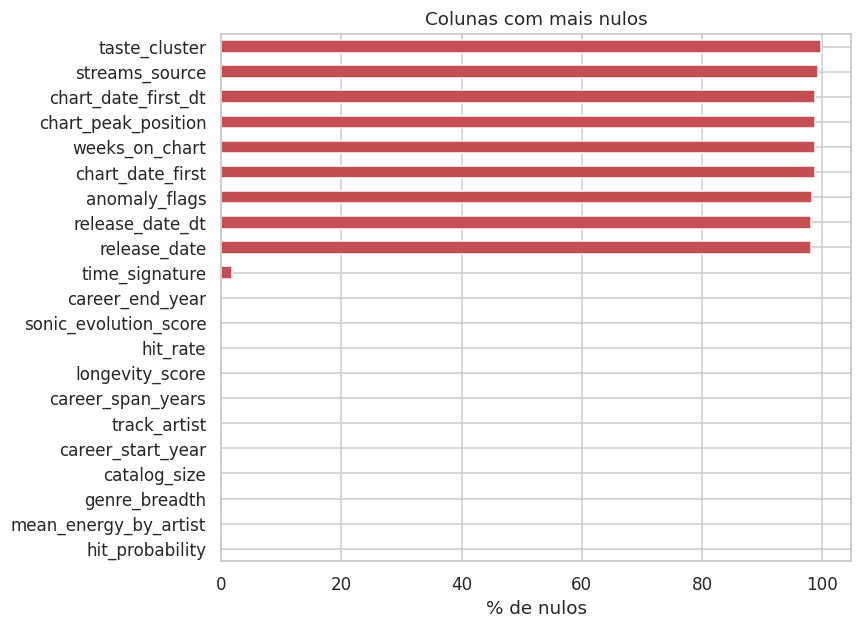

In [5]:
# 2.1 Nulos por coluna
nulos = pd.DataFrame({    
    "n_nulos":   df.isna().sum(), #verifica quantos valores nulos existem
    "pct_nulos": df.isna().mean() * 100, #verifica a porcentagem desses nulos
    "dtype":     df.dtypes.astype(str), #mostra o tipo
})
nulos = nulos[nulos["n_nulos"] > 0].sort_values("pct_nulos", ascending=False) #mostra, por ordem de crescente, quais são os maiores nulos
display(nulos)

#se tiver colunas com valores nulos, pegar os 30 maiores valores e fazer um gráfico, analisar se algumas colunas valem a pena serem colocadas na analise de amchine learning
if len(nulos):
    top = nulos.head(30).sort_values("pct_nulos")
    ax = top["pct_nulos"].plot(kind="barh", figsize=(8, max(3, 0.28 * len(top))), color="C3")
    ax.set_xlabel("% de nulos")
    ax.set_title("Colunas com mais nulos")
    plt.tight_layout()
    plt.show()

In [6]:
# 2.2 Duplicados
for c in ["track_id", "spotify_id"]:
    if c in df:
        print(f"{c}: {df[c].duplicated().sum():,} duplicados | {df[c].isna().sum():,} nulos")

# hash por linha: bem mais leve em memória que df.duplicated() com 80+ colunas
print(f"Linhas 100% duplicadas: {pd.util.hash_pandas_object(df, index=False).duplicated().sum():,}")

# Duplicados 'semânticos' (mesma música + artista com IDs diferentes)
chave = [c for c in ["title_normalized", "track_artist"] if c in df]
if len(chave) == 2:
    d = df.duplicated(subset=chave, keep=False)
    print(f"Faixas com mesmo título normalizado + artista: {d.sum():,} ({d.mean() * 100:.2f}%)")
    display(df.loc[d, chave + [c for c in ["album_name", "release_year", TARGET] if c in df]]
              .sort_values(chave).head(10))
else:
    print("Checagem de duplicados semânticos pulada (title_normalized não foi carregada — ver DROP_COLS).")

track_id: 0 duplicados | 0 nulos
Linhas 100% duplicadas: 0
Checagem de duplicados semânticos pulada (title_normalized não foi carregada — ver DROP_COLS).


In [7]:
# 2.3 Cardinalidade e colunas constantes
card = pd.DataFrame({
    "n_unicos":   df.nunique(dropna=False),
    "pct_unicos": df.nunique(dropna=False) / len(df) * 100,
    "dtype":      df.dtypes.astype(str),
}).sort_values("n_unicos")
display(card.head(25))   # menos únicos: candidatas a categóricas / constantes

constantes = card.index[card["n_unicos"] <= 1].tolist()
print("Colunas constantes (candidatas a remoção):", constantes)

,n_unicos,pct_unicos,dtype
release_year_precision_aug,1,0.000,bool
has_audio_features,1,0.000,bool
popularity_imputed_aug,1,0.000,bool
is_likely_spoken_word,2,0.000,bool
is_likely_live,2,0.000,bool
is_likely_instrumental,2,0.000,bool
has_anomaly,2,0.000,bool
explicit_flag,2,0.000,bool
source_dataset,2,0.000,category
streams_total_estimated,2,0.000,bool


Colunas constantes (candidatas a remoção): ['release_year_precision_aug', 'has_audio_features', 'popularity_imputed_aug']


In [8]:
# 2.4 Nulos estruturais: has_audio_features explica os NaNs / zeros nas features de áudio?
if "has_audio_features" in df:
    print(df["has_audio_features"].value_counts(dropna=False).to_frame("n"))
    print("\n% de nulos nas features de áudio, por has_audio_features:")
    display(df.groupby("has_audio_features")[AUDIO_FEATS].agg(lambda s: s.isna().mean() * 100).T.round(1))
    print("% de zeros exatos (valor 'placeholder' suspeito):")
    display(df.groupby("has_audio_features")[AUDIO_FEATS].agg(lambda s: (s == 0).mean() * 100).T.round(1))

                          n
has_audio_features         
True                1182354

% de nulos nas features de áudio, por has_audio_features:


has_audio_features,True
energy,0.000
valence,0.000
danceability,0.000
acousticness,0.000
instrumentalness,0.000
speechiness,0.000
liveness,0.000
loudness,0.000
tempo,0.000


% de zeros exatos (valor 'placeholder' suspeito):


has_audio_features,True
energy,0.000
valence,0.100
danceability,0.100
acousticness,0.100
instrumentalness,25.000
speechiness,0.100
liveness,0.000
loudness,0.100
tempo,0.000


In [9]:
# 2.5 Checagens de consistência (regras de domínio)
ano_atual = pd.Timestamp.today().year
checks = {
    "duration_ms <= 0":                        (df["duration_ms"] <= 0).sum(),
    "duração < 30 s":                          (df["duration_ms"] < 30_000).sum(),
    "duração > 20 min":                        (df["duration_ms"] > 20 * 60_000).sum(),
    "tempo == 0":                              (df["tempo"] == 0).sum(),
    "time_signature == 0":                     (df["time_signature"] == 0).sum(),
    "loudness > 0 dB":                         (df["loudness"] > 0).sum(),
    "features [0-1] fora do intervalo":        ((df[AUDIO01] < 0) | (df[AUDIO01] > 1)).any(axis=1).sum(),
    "popularidade fora de [0, 100]":           ((df[TARGET] < 0) | (df[TARGET] > 100)).sum(),
    "release_year fora de [1900, ano atual]":  ((df["release_year"] < 1900) | (df["release_year"] > ano_atual)).sum(),
    "decade != release_year//10*10":           (df["decade"] != (df["release_year"] // 10 * 10)).sum(),
    "ano de release_date != release_year":     (df["release_date_dt"].dt.year.notna()
                                                & (df["release_date_dt"].dt.year != df["release_year"])).sum(),
    "release_date não parseável":              (df["release_date_dt"].isna() & df["release_date"].notna()).sum(),
}
chk = pd.Series(checks).to_frame("n")
chk["pct"] = chk["n"] / len(df) * 100
display(chk)

,n,pct
duration_ms <= 0,0,0.000
duração < 30 s,1770,0.150
duração > 20 min,2637,0.223
tempo == 0,0,0.000
time_signature == 0,1228,0.104
loudness > 0 dB,0,0.000
features [0-1] fora do intervalo,0,0.000
"popularidade fora de [0, 100]",0,0.000
"release_year fora de [1900, ano atual]",0,0.000
decade != release_year//10*10,0,0.000


## 3. Univariada numérica

In [11]:
desc = df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"]      = df[num_cols].skew()
desc["pct_zeros"] = (df[num_cols] == 0).mean() * 100
desc["pct_nulos"] = df[num_cols].isna().mean() * 100
display(desc)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,pct_zeros,pct_nulos
release_year,"1,182,354.000","2,011.923",6.949,"1,957.000","2,000.000","2,006.000","2,012.000","2,018.000","2,023.000","2,023.000",-0.300,0.000,0.000
duration_ms,"1,182,354.000","249,129.722","148,277.159","2,073.000","57,693.000","181,253.000","225,497.500","286,140.000","650,738.170","6,000,495.000",10.349,0.000,0.000
energy,"1,182,354.000",0.641,0.269,0.000,0.018,0.457,0.694,0.872,0.994,1.000,-0.624,0.002,0.000
valence,"1,182,354.000",0.457,0.268,0.000,0.033,0.228,0.440,0.674,0.964,1.000,0.168,0.127,0.000
danceability,"1,182,354.000",0.540,0.185,0.000,0.110,0.415,0.553,0.680,0.890,0.993,-0.308,0.101,0.000
acousticness,"1,182,354.000",0.319,0.353,0.000,0.000,0.007,0.144,0.632,0.993,0.996,0.724,0.061,0.000
instrumentalness,"1,182,354.000",0.249,0.364,0.000,0.000,0.000,0.002,0.599,0.960,1.000,0.989,25.038,0.000
speechiness,"1,182,354.000",0.093,0.126,0.000,0.026,0.037,0.051,0.090,0.903,0.971,4.447,0.101,0.000
liveness,"1,182,354.000",0.222,0.200,0.000,0.038,0.098,0.134,0.291,0.952,1.000,1.961,0.012,0.000
loudness,"1,182,354.000",-8.945,5.649,-58.100,-29.832,-10.778,-7.425,-5.265,-1.802,0.000,-1.923,0.102,0.000


,skew
stream_density,64.267
streams_total,40.233
energy_loudness_ratio,16.491
hit_rate,16.083
hit_probability,11.780
duration_ms,10.349
catalog_size,9.516
danceability_trend,5.503
speechiness,4.447
acoustic_synthetic_ratio,4.125


Em escala log1p: ['stream_density', 'streams_total', 'energy_loudness_ratio', 'hit_rate', 'hit_probability', 'duration_ms', 'catalog_size', 'speechiness', 'acoustic_synthetic_ratio', 'fp_speechiness', 'genre_breadth', 'artist_stream_mean_log']


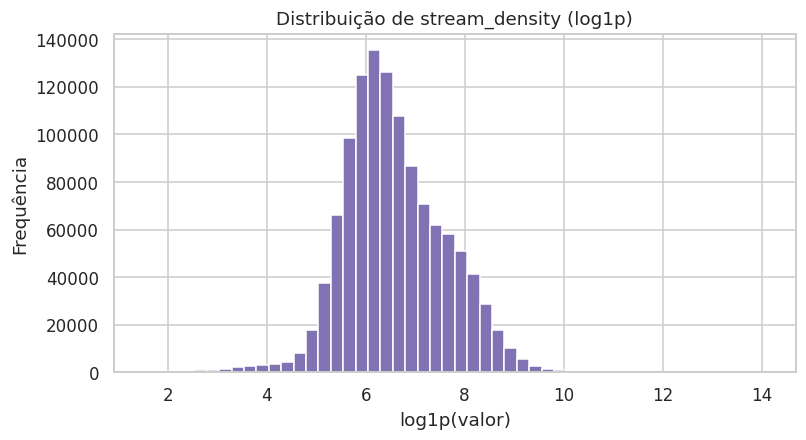

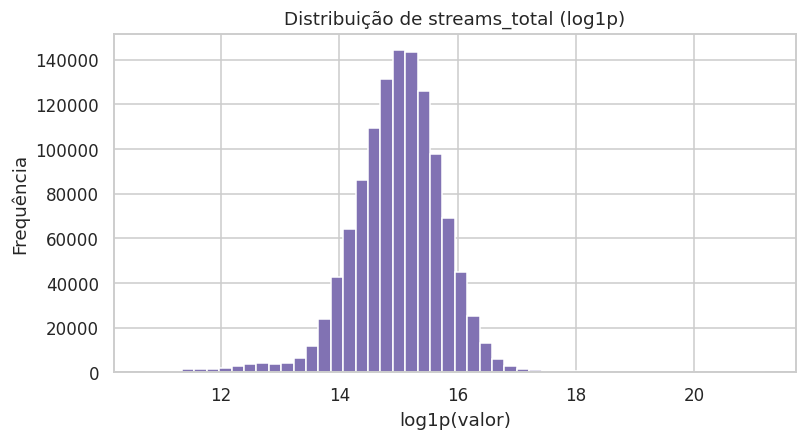

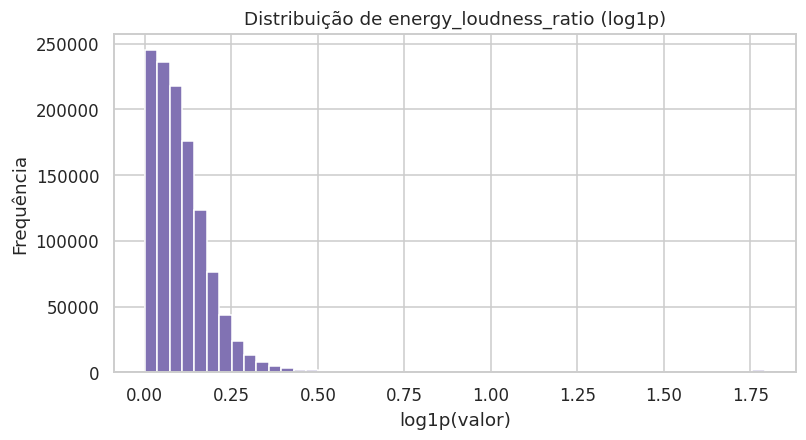

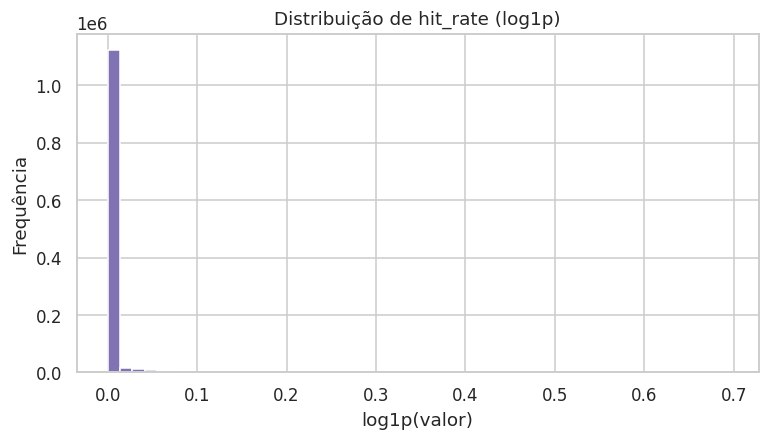

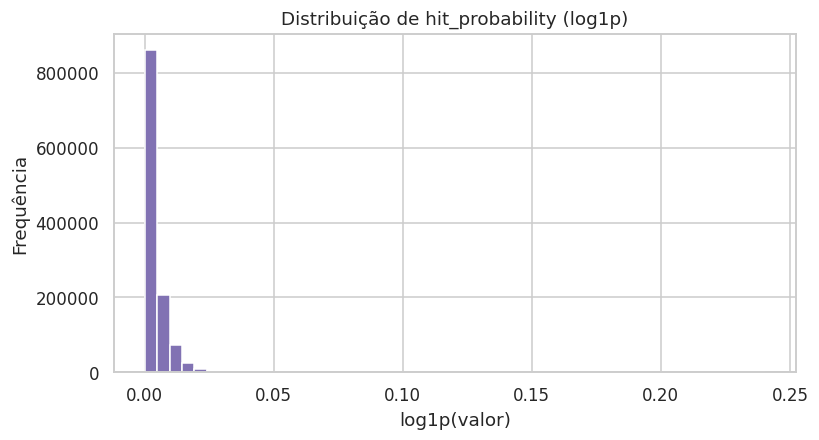

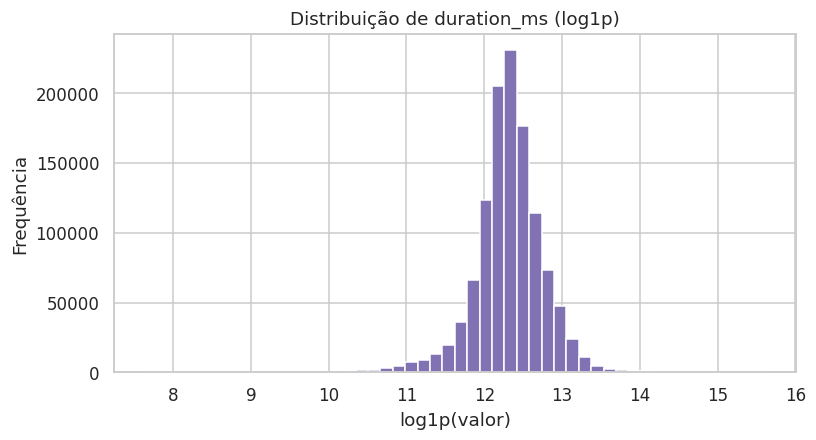

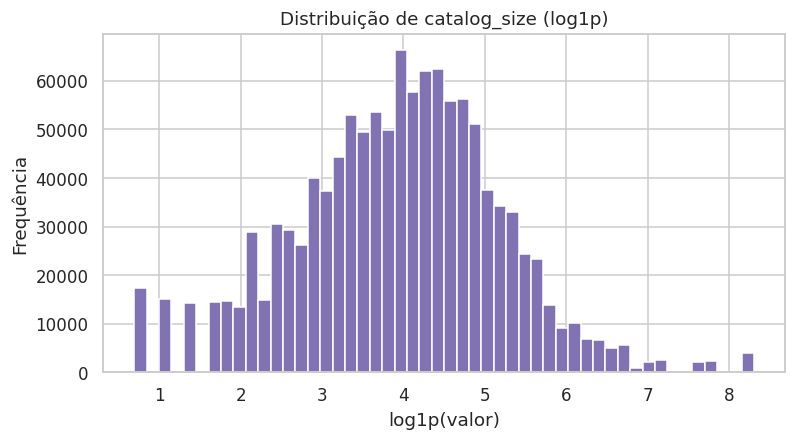

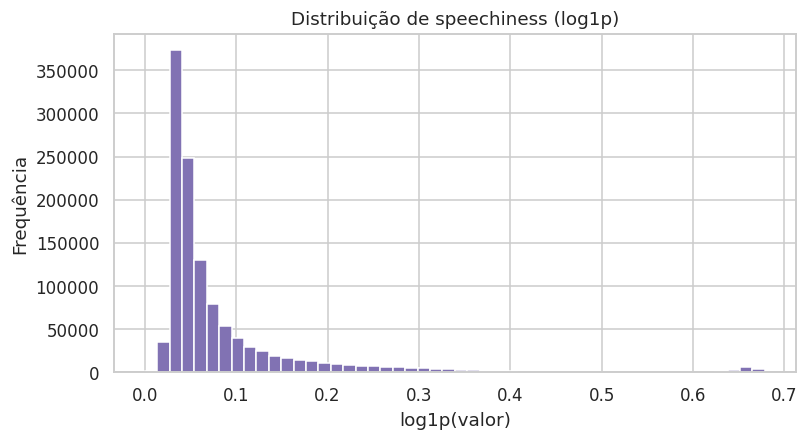

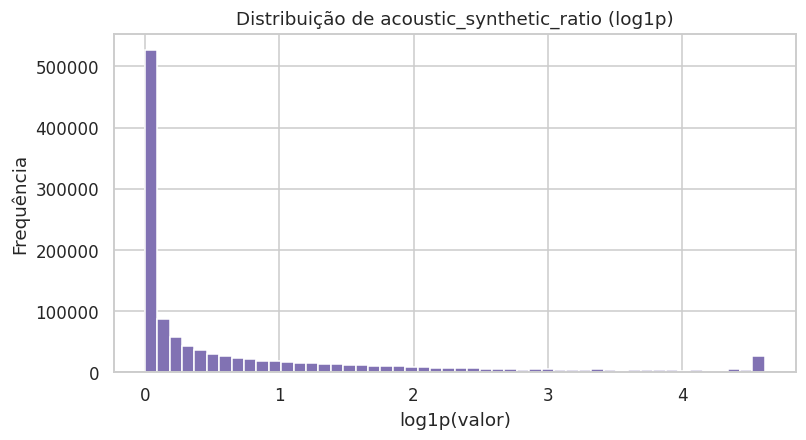

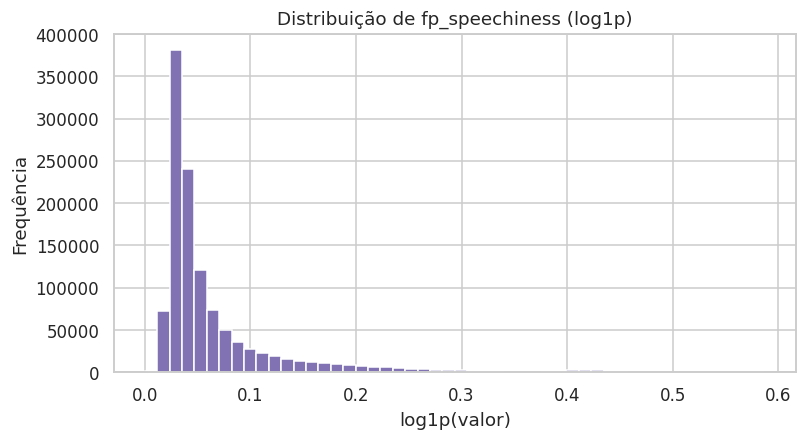

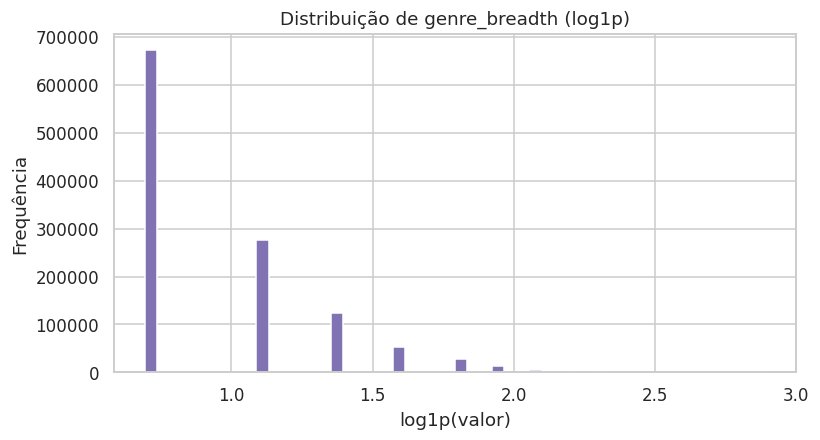

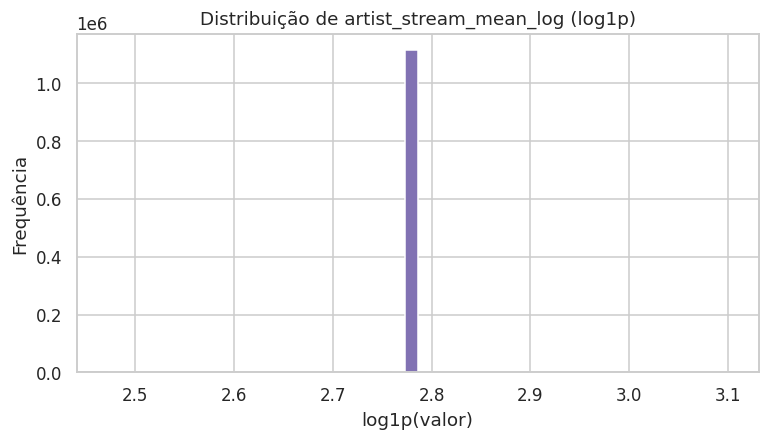

In [35]:
# Variáveis muito assimétricas -> olhar em escala log
skew = df[num_cols].skew().sort_values(key=abs, ascending=False)
display(skew.head(15).to_frame("skew"))

def plot_hists(cols, log1p=False, color="C0"):
    for c in cols:
        dados = pd.to_numeric(df[c], errors="coerce").dropna()

        if log1p:
            dados = dados[dados >= 0]
            dados = np.log1p(dados)

        dados = dados[np.isfinite(dados)]

        if dados.empty:
            print(f"Coluna {c} sem dados válidos.")
            continue

        plt.figure(figsize=(8, 4))
        plt.hist(dados, bins=50, color=color, edgecolor="white")
        plt.title(f"Distribuição de {c}" +
                  (" (log1p)" if log1p else ""))
        plt.xlabel("log1p(valor)" if log1p else c)
        plt.ylabel("Frequência")
        plt.show()

        
pesadas = [c for c in skew.index
           if abs(skew[c]) > 2 and df[c].min() >= 0 and df[c].nunique() > 10][:12]
print("Em escala log1p:", pesadas)
plot_hists(pesadas, log1p=True, color="C4")

In [14]:
# Outliers pelo critério IQR (1.5 x IQR)
def resumo_outliers(d, cols):
    q1, q3 = d[cols].quantile(.25), d[cols].quantile(.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((d[cols] < lo) | (d[cols] > hi)).sum()
    return pd.DataFrame({"n_outliers": n, "pct": n / len(d) * 100,
                         "lim_inf": lo, "lim_sup": hi}).sort_values("pct", ascending=False)

cols_out = [c for c in num_cols if df[c].nunique() > 10]
display(resumo_outliers(df, cols_out).head(25))

,n_outliers,pct,lim_inf,lim_sup
acoustic_synthetic_ratio,194358,16.438,-2.560,4.284
fp_speechiness,140213,11.859,-0.032,0.135
speechiness,139815,11.825,-0.041,0.168
stream_density,121571,10.282,"-1,204.481","2,977.420"
genre_breadth,108808,9.203,-0.500,3.500
career_end_year,102372,8.658,"2,010.500","2,030.500"
catalog_size,98035,8.292,-118.500,253.500
liveness,93796,7.933,-0.192,0.581
hit_rate,87723,7.419,0.000,0.000
hit_probability,77169,6.527,-0.005,0.012


## 4. Categóricas e booleanas

,n_categorias
genre_l1,18
key_name,12
mode_name,2
era,4
tempo_band,5
emotional_arc,4
mood_cluster,8
taste_cluster,246
source_dataset,2
streams_source,2


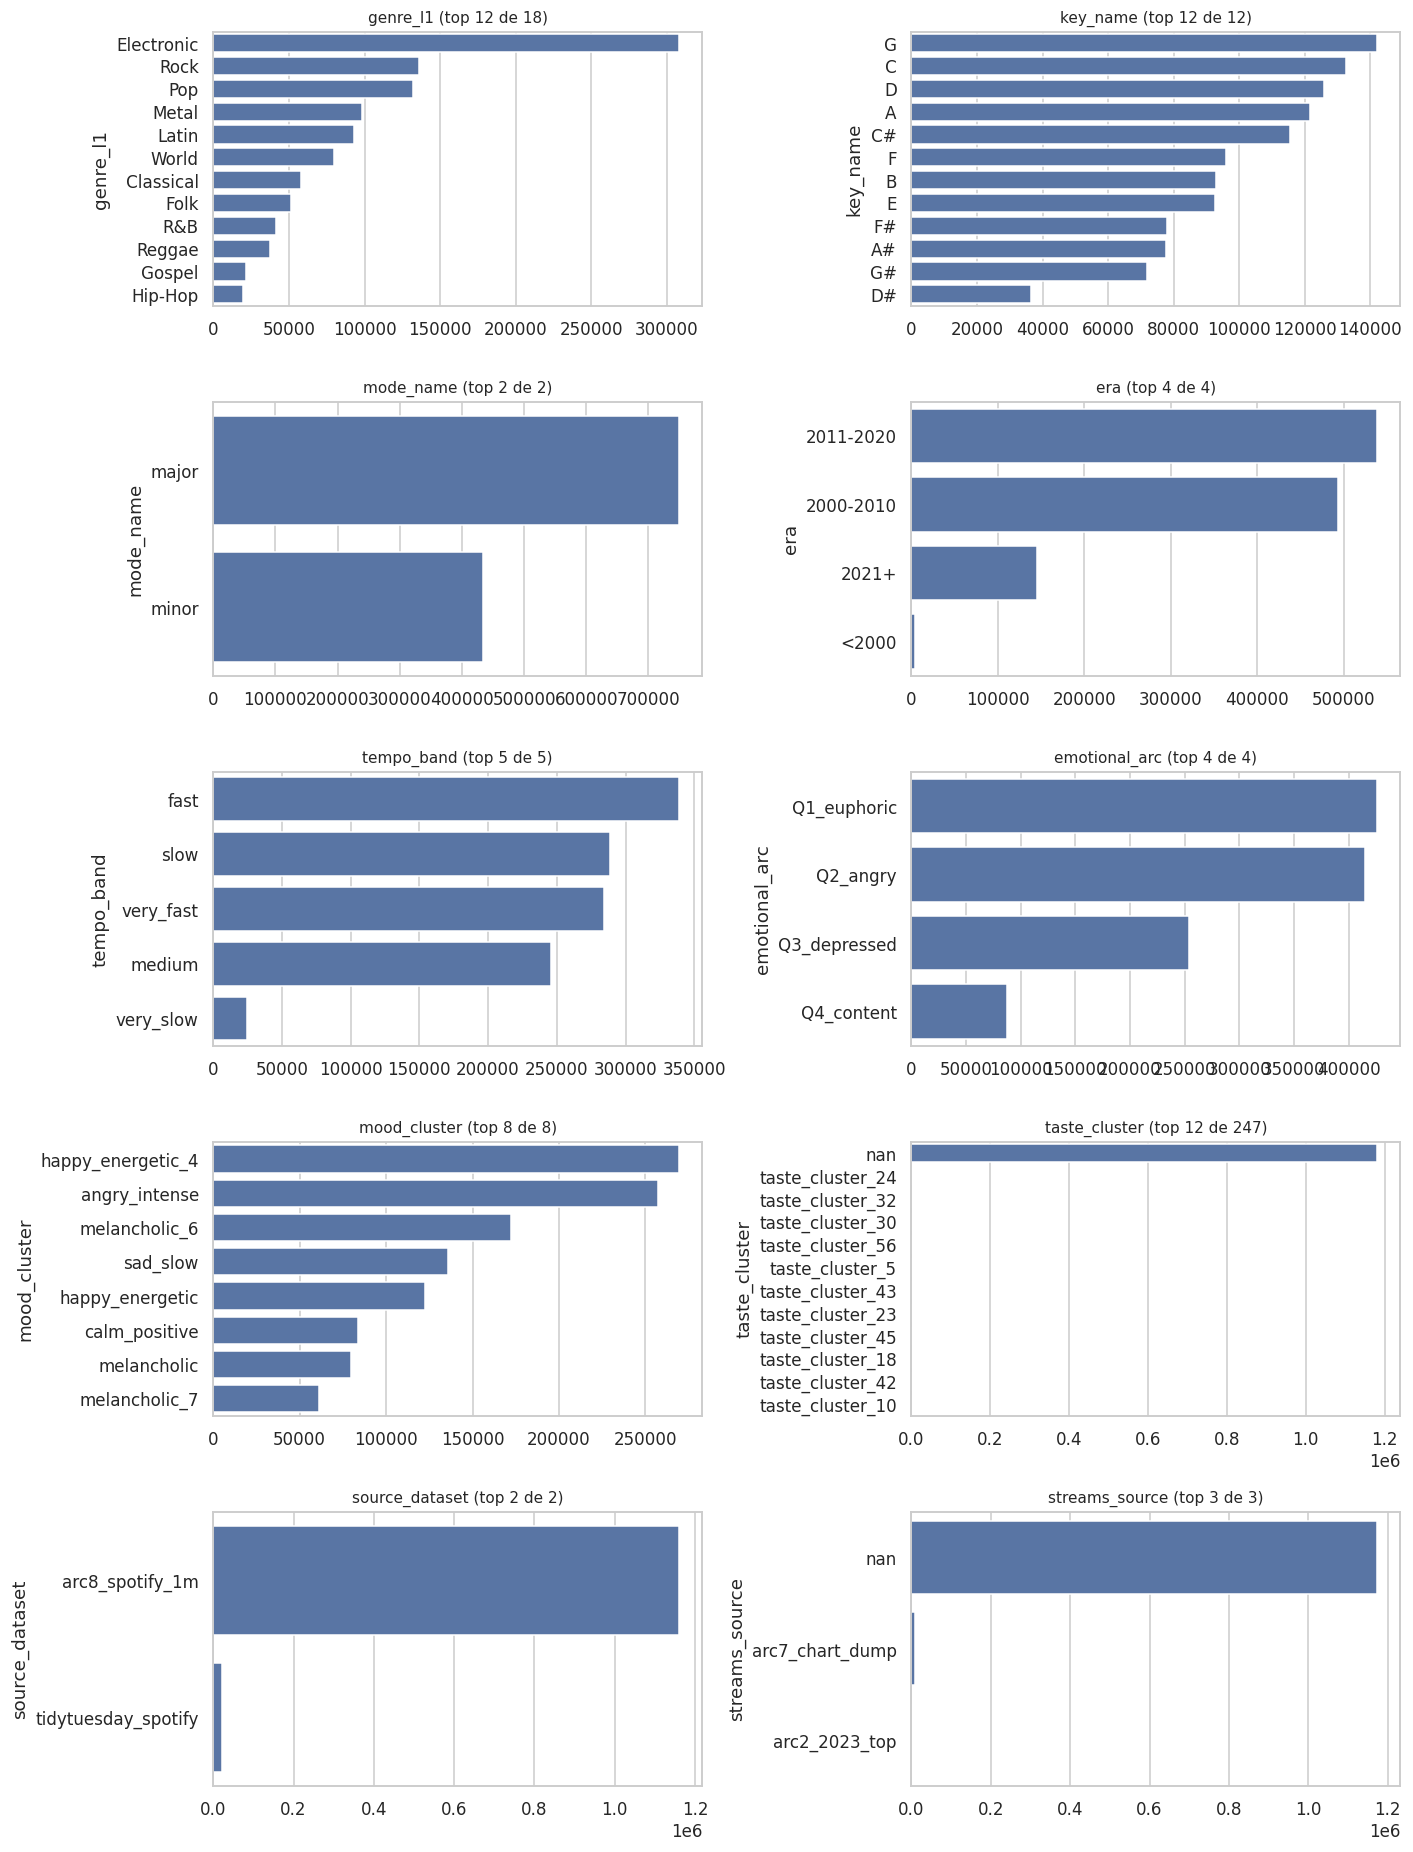

In [15]:
CATS = [c for c in ["genre_l1", "key_name", "mode_name", "era", "tempo_band", "emotional_arc",
                    "mood_cluster", "taste_cluster", "source_dataset", "streams_source"] if c in df]
display(df[CATS].nunique().to_frame("n_categorias"))

def plot_top(cols, n=12, ncols=2):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 3.4 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        vc = df[c].value_counts(dropna=False).head(n)
        sns.barplot(x=vc.values, y=vc.index.astype(str), ax=ax, color="C0")
        ax.set_title(f"{c} (top {min(n, df[c].nunique(dropna=False))} de {df[c].nunique(dropna=False)})", fontsize=10)
        ax.set_xlabel("")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

plot_top(CATS)

In [16]:
# Alta cardinalidade: só o topo
for c in [c for c in ["genre_l2", "genre_raw"] if c in df]:
    print(f"\n{c}: {df[c].nunique():,} valores únicos | {df[c].isna().mean() * 100:.1f}% nulos")
    display(df[c].value_counts().head(15).to_frame("n"))


genre_l2: 99 valores únicos | 0.0% nulos


,n
genre_l2,
Mood Pop,23937
Black Metal,21852
Gospel,21621
Ambient,21389
Acoustic,21097
Alt-Rock,20918
Emo,20845
Indian,20583
K-Pop,20004


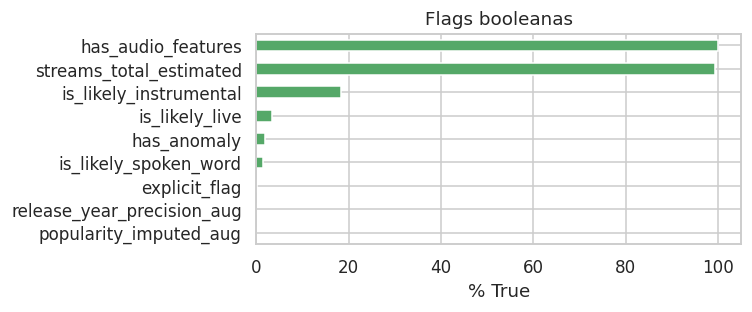

In [17]:
# Booleanas: % de True
pct_true = (df[bool_cols].mean() * 100).sort_values()
ax = pct_true.plot(kind="barh", figsize=(7, max(3, 0.3 * len(pct_true))), color="C2")
ax.set_xlabel("% True")
ax.set_title("Flags booleanas")
plt.tight_layout()
plt.show()

## 5. Evolução temporal
Cuidado: a popularidade do Spotify tende a favorecer lançamentos recentes — compare sempre com o volume de faixas por ano.

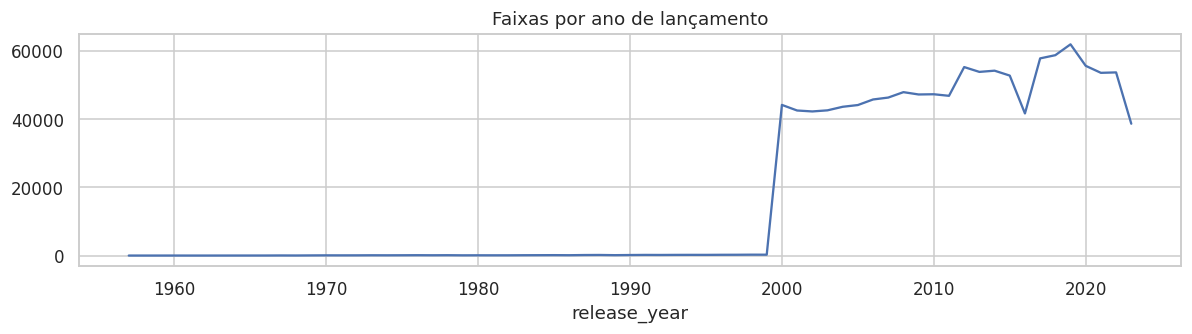

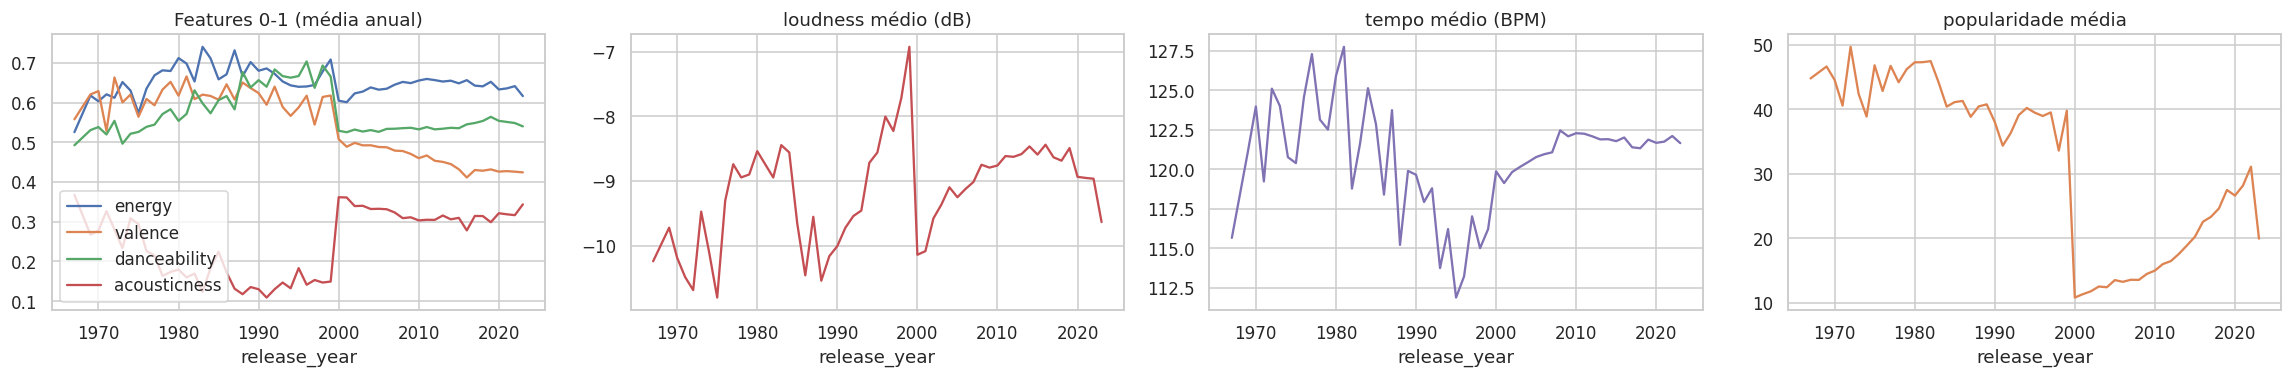

In [18]:
n_ano = df.groupby("release_year").size()

fig, ax = plt.subplots(figsize=(11, 3.2))
n_ano.plot(ax=ax)
ax.set_title("Faixas por ano de lançamento")
plt.tight_layout()
plt.show()

validos = n_ano[n_ano >= 30].index          # evita médias instáveis em anos com poucas faixas
por_ano = df[df["release_year"].isin(validos)].groupby("release_year")[AUDIO_FEATS + [TARGET]].mean()

fig, axes = plt.subplots(1, 4, figsize=(21, 3.6))
por_ano[[c for c in ["energy", "valence", "danceability", "acousticness"] if c in por_ano]].plot(ax=axes[0])
por_ano["loudness"].plot(ax=axes[1], color="C3");  axes[1].set_title("loudness médio (dB)")
por_ano["tempo"].plot(ax=axes[2], color="C4");     axes[2].set_title("tempo médio (BPM)")
por_ano[TARGET].plot(ax=axes[3], color="C1");      axes[3].set_title("popularidade média")
axes[0].set_title("Features 0-1 (média anual)")
plt.tight_layout()
plt.show()

In [19]:
if "decade" in df:
    display(df.groupby("decade").agg(
        n=("track_id", "count"),
        duracao_min=("duration_ms", lambda s: s.mean() / 60000),
        **{f"{c}_media": (c, "mean") for c in ["energy", "valence", "danceability", "acousticness", "loudness", TARGET] if c in df}
    ).round(3))

,n,duracao_min,energy_media,valence_media,danceability_media,acousticness_media,loudness_media,track_popularity_media
decade,,,,,,,,
1950,3,2.436,0.714,0.913,0.562,0.538,-5.847,44.333
1960,132,3.626,0.591,0.616,0.514,0.342,-9.922,46.447
1970,783,4.285,0.638,0.609,0.540,0.244,-9.687,44.261
1980,1088,4.467,0.694,0.627,0.610,0.156,-9.503,42.131
1990,2076,4.418,0.665,0.599,0.668,0.143,-8.558,37.925
2000,446441,4.369,0.631,0.488,0.531,0.334,-9.305,12.732
2010,530302,4.134,0.652,0.441,0.543,0.306,-8.589,20.428
2020,201529,3.714,0.633,0.426,0.549,0.324,-9.081,26.929


## 6. Correlações
Spearman é mais seguro aqui (muitas variáveis assimétricas / com zeros).

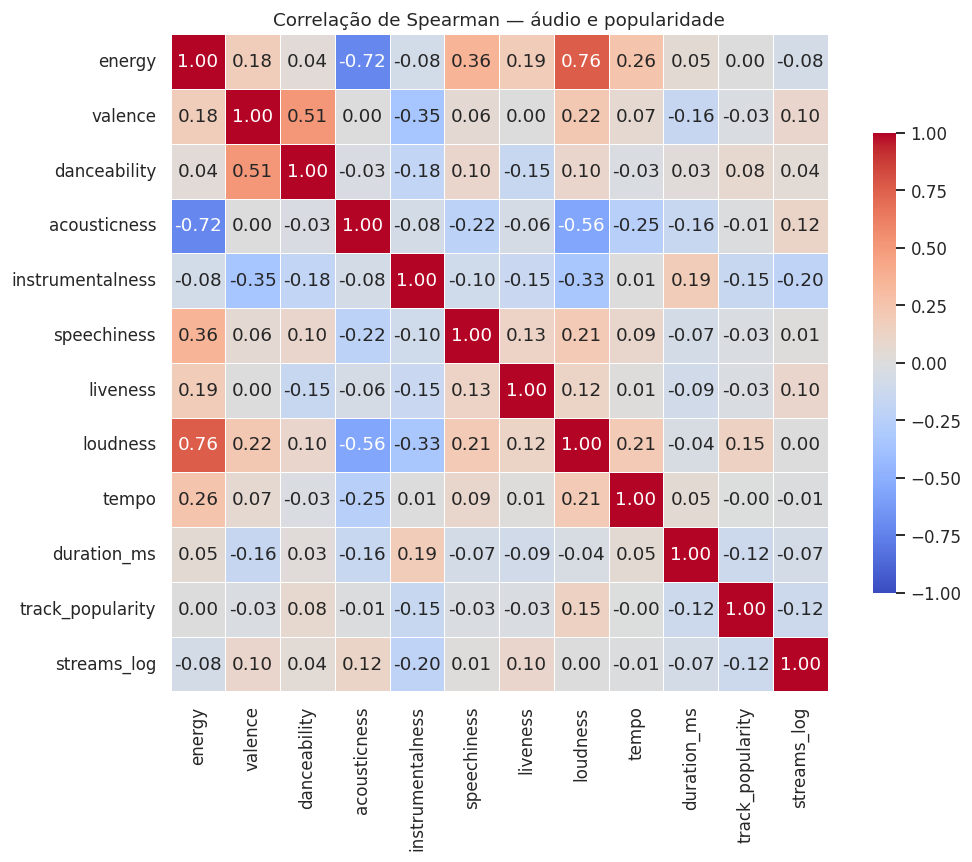

In [20]:
corr_cols = [c for c in AUDIO_FEATS + ["duration_ms", TARGET, "streams_log"] if c in df]
corr = dfs[corr_cols].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .7})
plt.title("Correlação de Spearman — áudio e popularidade")
plt.tight_layout()
plt.show()

In [23]:
# Pares muito correlacionados (redundância / multicolinearidade)
corr_all = dfs[num_cols].corr(method="spearman")
pares = corr_all.where(np.triu(np.ones(corr_all.shape, dtype=bool), k=1)).stack()
pares = pares[pares.abs() >= 0.9].sort_values(key=abs, ascending=False)
print(f"{len(pares)} pares com |rho| >= 0.90")
display(pares.head(40).to_frame("spearman"))

28 pares com |rho| >= 0.90


,,spearman
release_year,track_age_days,-1.000
decade,mean_valence_by_decade,-1.000
acousticness,acoustic_synthetic_ratio,1.000
mean_energy_by_decade,acousticness_decline_idx,-0.999
instrumentalness,fp_instrumentalness,0.993
mean_energy_by_decade,mean_loudness_by_decade,0.992
loudness,loudness_war_index,0.991
mean_loudness_by_decade,acousticness_decline_idx,-0.989
acoustic_synthetic_ratio,fp_acousticness,0.987
acousticness,fp_acousticness,0.987


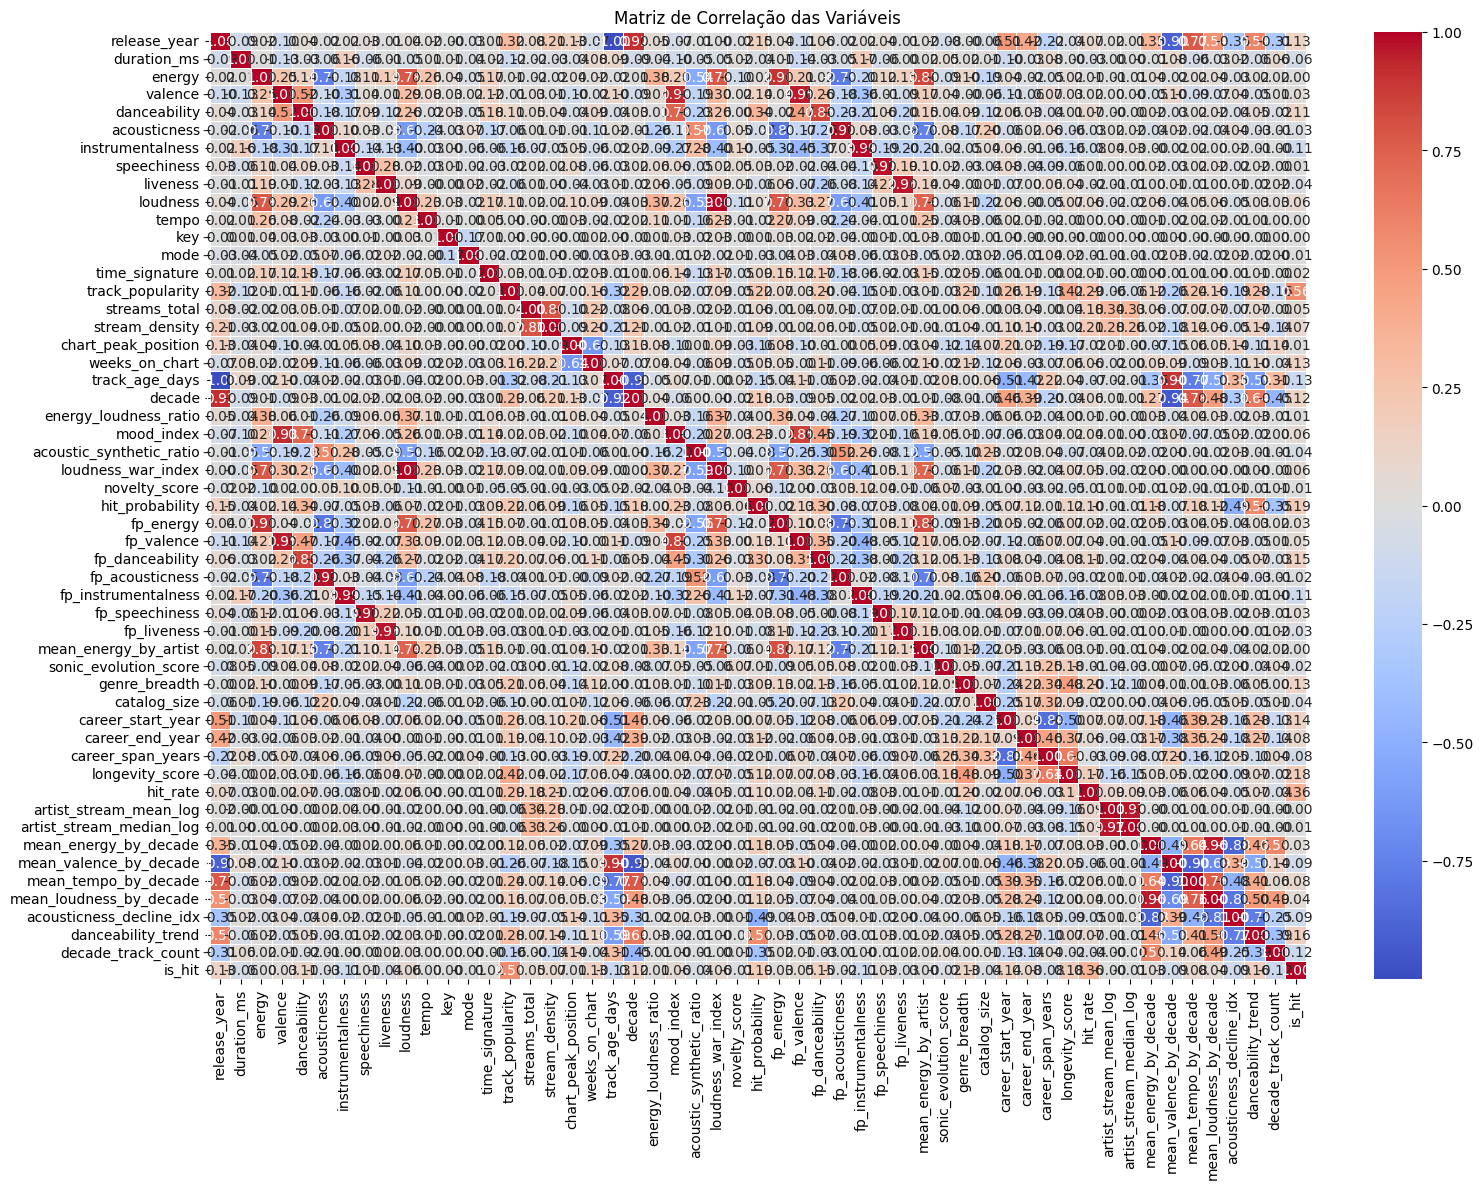

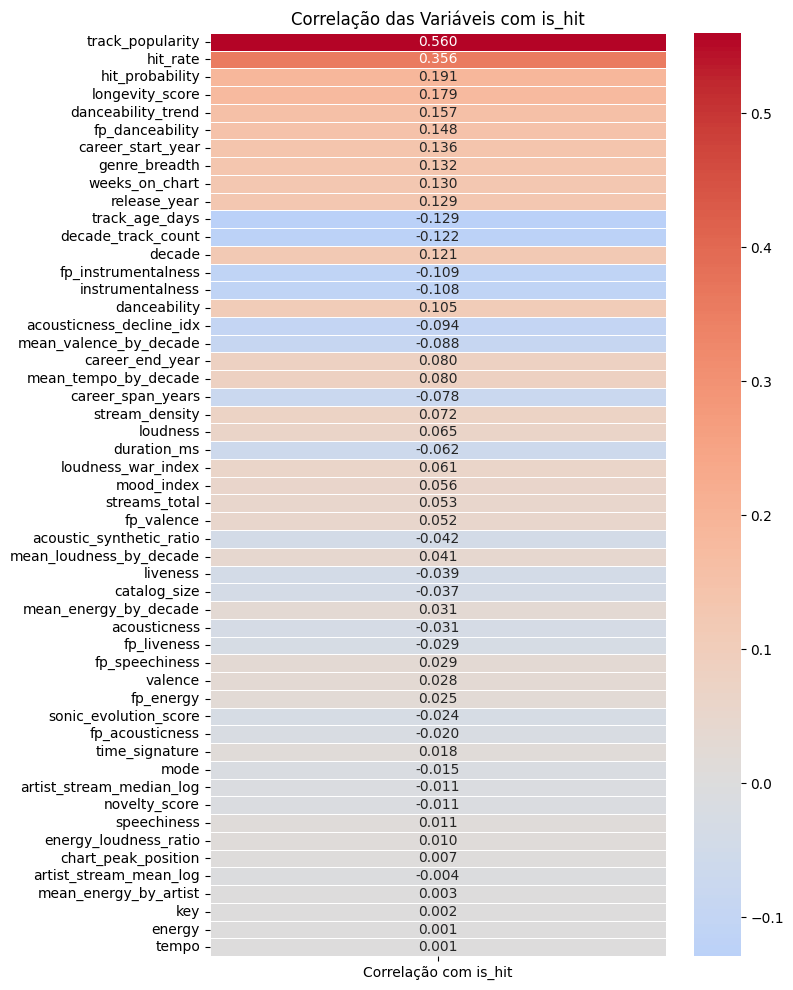

Variáveis mais correlacionadas com is_hit:


,Correlação com is_hit
track_popularity,0.559970
hit_rate,0.355627
hit_probability,0.191217
longevity_score,0.178828
danceability_trend,0.157041
fp_danceability,0.147508
career_start_year,0.135801
genre_breadth,0.132391
weeks_on_chart,0.129971
release_year,0.129038


In [8]:

# Correlação com track_popularity
correlacoes = df.select_dtypes(include='number').corr()['track_popularity']

# Remover track_popularity e is_hit
correlacoes = correlacoes.drop(
    labels=['track_popularity', 'is_hit'],
    errors='ignore'
)

# Ordenar do mais relacionado para o menos relacionado
correlacoes = correlacoes.reindex(
    correlacoes.abs().sort_values(ascending=False).index
)

# Exibir lista
print("Variáveis da mais relacionada para a menos relacionada:\n")

for variavel, valor in correlacoes.items():
    print(f"{variavel}: {valor:.4f}")


Variáveis da mais relacionada para a menos relacionada:

longevity_score: 0.4180
track_age_days: -0.3193
release_year: 0.3193
decade: 0.2913
hit_rate: 0.2885
danceability_trend: 0.2790
mean_valence_by_decade: -0.2615
career_start_year: 0.2588
mean_tempo_by_decade: 0.2370
hit_probability: 0.2212
genre_breadth: 0.2087
fp_danceability: 0.1959
career_end_year: 0.1913
acousticness_decline_idx: -0.1859
mean_loudness_by_decade: 0.1637
weeks_on_chart: 0.1630
decade_track_count: -0.1629
instrumentalness: -0.1582
fp_instrumentalness: -0.1547
career_span_years: -0.1273
mean_energy_by_decade: 0.1234
duration_ms: -0.1197
danceability: 0.1070
loudness: 0.1065
catalog_size: -0.1030
loudness_war_index: 0.0929
stream_density: 0.0719
acoustic_synthetic_ratio: -0.0715
fp_energy: 0.0710
acousticness: -0.0617
liveness: -0.0589
artist_stream_median_log: -0.0566
artist_stream_mean_log: -0.0553
novelty_score: -0.0466
fp_acousticness: -0.0424
streams_total: 0.0402
fp_liveness: -0.0348
fp_valence: 0.0339
energy

## 7. Bivariadas contra popularidade / streams

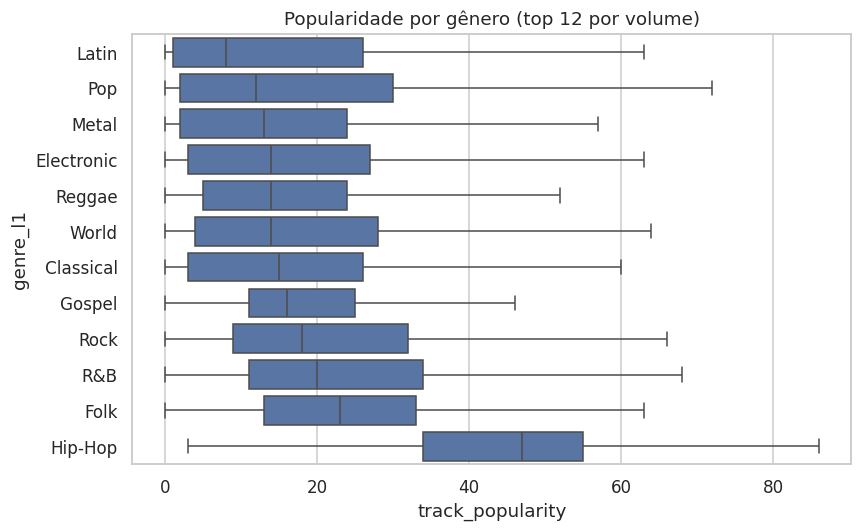

In [25]:
# 7.2 Popularidade por gênero (top 12 por volume)
if "genre_l1" in dfs:
    top_g = df["genre_l1"].value_counts().head(12).index
    sub = dfs[dfs["genre_l1"].isin(top_g)]
    ordem = sub.groupby("genre_l1", observed=True)[TARGET].median().sort_values().index
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=sub, y="genre_l1", x=TARGET, order=ordem, showfliers=False, color="C0")
    plt.title("Popularidade por gênero (top 12 por volume)")
    plt.tight_layout()
    plt.show()

In [ ]:
# catalog_size bate com a contagem real de faixas no dataset?
if "catalog_size" in df:
    t = df.groupby("track_artist").agg(n=("track_id", "count"), cat=("catalog_size", "first"))
    print(f"catalog_size == nº de faixas no dataset: {(t['n'] == t['cat']).mean() * 100:.1f}% dos artistas")
    display(t.assign(dif=t["cat"] - t["n"])["dif"].describe().to_frame("catalog_size - n_faixas"))

## 10. Conclusões e próximos passos
Preencha ao final da exploração:

- **Qualidade:** colunas com muitos nulos? placeholders (zeros) em faixas sem `has_audio_features`? duplicados?
- **Distribuições:** quais variáveis precisam de log / winsorização? `instrumentalness`, `speechiness` e `streams_total` costumam pedir isso.
- **Tendências:** como loudness, energy, valence e acousticness mudam por década?
- **Alvo:** popularidade enviesada para faixas recentes? quanto é imputado (`popularity_imputed_aug`)?
- **Redundância:** quais colunas remover (constantes, `fp_*` duplicadas, pares com |rho| > 0.9)?
- **Hierarquia dos dados:** faixas aninhadas em artistas → usar split agrupado.
- **Hipóteses para testar** (estatística ou modelo): ...